<a id="top"></a>

# Why Do Language Learners Drop Out?

**Analysis of factors associated with dropout before reaching B2**

Why are language learners dropping out before reaching B2, and what factors are associated with learner retention?

The dataset contains records of 45,000 learners, measured across 18 variables.

Dataset source: https://www.kaggle.com/datasets/sergionefedov/language-learning-to-fluency-who-gets-there

## Table of Contents

1. [Setup and Data Preparation](#sec-1)
2. [Data Quality Checks](#sec-2)
3. [Creating Groups](#sec-3)
4. [Overall Dropout](#sec-4)
    - [4.1 Dropout vs Did Not Drop Out](#sec-4-1)
    - [4.2 Distribution of CEFR Levels Reached](#sec-4-2)
5. [Factor Analysis](#sec-5)
    - [5.1 Motivation](#sec-5-1)
    - [5.2 Consistency](#sec-5-2)
    - [5.3 Comprehensible Input](#sec-5-3)
    - [5.4 Active Use](#sec-5-4)
    - [5.5 Study Hours](#sec-5-5)
    - [5.6 Study Hours and Active Use](#sec-5-6)
    - [5.7 Knowledge of Prior and Related Languages](#sec-5-7)
    - [5.8 Average Learning Behaviours by Dropout Status](#sec-5-8)
6. [Ranking the Factors Using Pearson Correlation](#sec-6)
7. [Loading the Data to PostgreSQL](#sec-7)

**Related file:** the SQL analysis (dropout rates by FSI category and by combinations of study hours, active use and comprehensible input) is in `Language_learning.sql`.

*Tools: Python (pandas, NumPy, matplotlib), PostgreSQL.*

<a id="sec-1"></a>

## 1. Setup and Data Preparation

*To run this notebook, download `language_learning_fluency.csv` from the Kaggle link above and place it in the same folder as the notebook.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# The CSV must sit in the same folder as this notebook
df = pd.read_csv('language_learning_fluency.csv')

In [2]:
df.head()

,learner_id,fsi_category,related_language,prior_languages,age_started,total_study_hours,active_use_share,immersion_months,speaking_practice,feedback_quality,comprehensible_input_hours,uses_srs,motivation,consistency,accent_nativelike,cefr_level,reached_fluency,dropped_out
0,LNR000000,2,0,0,14,590,0.276,0.0,0.61,1.27,430,0,4.96,7.29,6.66,A2,0,0
1,LNR000001,1,1,1,28,960,0.294,0.0,4.50,7.63,600,0,4.20,6.31,3.90,C1,1,0
2,LNR000002,2,0,0,14,270,0.132,0.0,8.53,0.00,120,1,1.93,6.80,7.57,A1,0,1
3,LNR000003,4,0,0,33,70,0.266,6.5,8.52,5.59,40,0,6.60,9.17,3.84,A0,0,0
4,LNR000004,2,0,0,35,780,0.746,0.0,5.80,4.74,470,1,1.90,6.48,5.97,C1,1,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   learner_id                  45000 non-null  str    
 1   fsi_category                45000 non-null  int64  
 2   related_language            45000 non-null  int64  
 3   prior_languages             45000 non-null  int64  
 4   age_started                 45000 non-null  int64  
 5   total_study_hours           45000 non-null  int64  
 6   active_use_share            45000 non-null  float64
 7   immersion_months            45000 non-null  float64
 8   speaking_practice           45000 non-null  float64
 9   feedback_quality            45000 non-null  float64
 10  comprehensible_input_hours  45000 non-null  int64  
 11  uses_srs                    45000 non-null  int64  
 12  motivation                  45000 non-null  float64
 13  consistency                 45000 non-null

<a id="sec-2"></a>

## 2. Data Quality Checks

In [4]:
df.isnull().sum()

learner_id                    0
fsi_category                  0
related_language              0
prior_languages               0
age_started                   0
total_study_hours             0
active_use_share              0
immersion_months              0
speaking_practice             0
feedback_quality              0
comprehensible_input_hours    0
uses_srs                      0
motivation                    0
consistency                   0
accent_nativelike             0
cefr_level                    0
reached_fluency               0
dropped_out                   0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

<a id="sec-3"></a>

## 3. Creating Groups

In [6]:
df['consistency_group'] = pd.cut(
    df['consistency'],
    bins=[0, 3, 6, 8, 10],
    labels=['Low', 'Moderate', 'High', 'Very High']
)

In [7]:
df['active_use_group'] = pd.qcut(
    df['active_use_share'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

In [8]:

df['input_hours_group'] = pd.qcut(
    df['comprehensible_input_hours'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

<a id="sec-4"></a>

## 4. Overall Dropout

<a id="sec-4-1"></a>

### 4.1 Dropout vs Did Not Drop Out

In [9]:
# create column
df['dropped_out'].value_counts()

dropped_out
0    28320
1    16680
Name: count, dtype: int64

In [10]:
df['dropped_out'].value_counts(normalize=True).mul(100).round(2)

dropped_out
0    62.93
1    37.07
Name: proportion, dtype: float64

In [11]:
pd.crosstab(df['dropped_out'], df['reached_fluency'], margins=True)

reached_fluency,0,1,All
dropped_out,,,
0,12227,16093,28320
1,16680,0,16680
All,28907,16093,45000


Approximately 37% of learners in the dataset dropped out before reaching B2, while 63% did not.

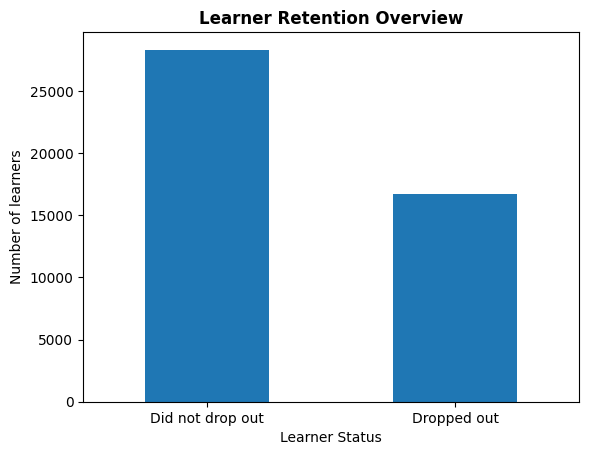

In [12]:
# Barplot for comparing amount of learners who dropped out vs not
df['dropped_out'].value_counts().rename({
    0: 'Did not drop out',
    1: 'Dropped out'
}).plot.bar(rot=0)

plt.xlabel('Learner Status')
plt.ylabel('Number of learners')
plt.title('Learner Retention Overview', fontweight='bold')
plt.show()

<a id="sec-4-2"></a>

### 4.2 Distribution of CEFR Levels Reached

In [13]:
cefr_order = ['A0', 'A1', 'A2', 'B1', 'B2', 'C1', 'C2']

cefr_percentage = (df['cefr_level'].value_counts(normalize=True).reindex(cefr_order).mul(100).round(2))

print(cefr_percentage)

cefr_level
A0    11.62
A1    14.79
A2    24.00
B1    13.82
B2    14.20
C1    11.91
C2     9.65
Name: proportion, dtype: float64


Mode CEFR level: A2.

Least frequent CEFR level: C2.

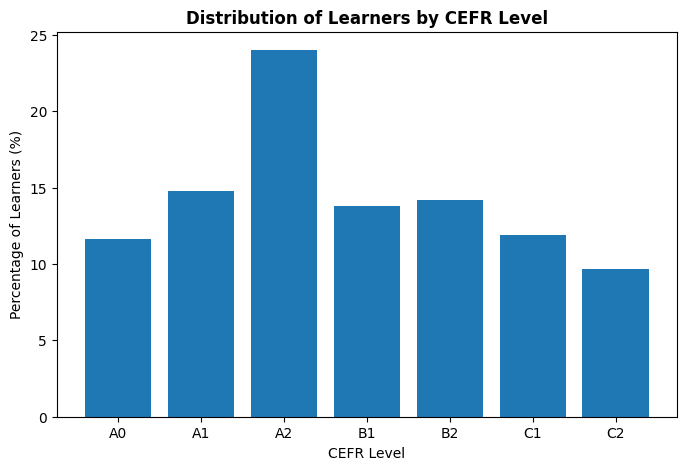

In [14]:
# Creating a bar chart
plt.figure(figsize=(8, 5))

plt.bar(cefr_percentage.index, cefr_percentage.values)

plt.xlabel('CEFR Level')
plt.ylabel('Percentage of Learners (%)')
plt.title('Distribution of Learners by CEFR Level', fontweight='bold')

plt.show()

<a id="sec-5"></a>

## 5. Factor Analysis

<a id="sec-5-1"></a>

### 5.1 Motivation

In [15]:
df.groupby('dropped_out')['motivation'].mean().round(2)

dropped_out
0    5.23
1    4.58
Name: motivation, dtype: float64

Learners who did not drop out had an average motivation score of 5.23, compared with 4.58 among learners who dropped out.

In [16]:
df['motivation_group'] = pd.cut(df['motivation'], bins=[0, 3, 6, 8, 10],
    labels=['Low', 'Medium', 'High', 'Very High'],
    include_lowest=True)

df.groupby('motivation_group')['dropped_out'].mean().mul(100).round(2)

motivation_group
Low          47.66
Medium       38.12
High         31.11
Very High    24.58
Name: dropped_out, dtype: float64

As motivation increases, dropout decreases. The difference between Low and Very High motivation is 23.1 percentage points.

<a id="sec-5-2"></a>

### 5.2 Consistency

In [17]:
df.groupby('dropped_out')['consistency'].mean().round(2)

dropped_out
0    6.67
1    6.03
Name: consistency, dtype: float64

In [18]:
df.groupby('consistency_group', observed=True)['dropped_out'].mean().mul(100).round(2)

consistency_group
Low          48.79
Moderate     42.74
High         35.91
Very High    27.81
Name: dropped_out, dtype: float64

<a id="sec-5-3"></a>

### 5.3 Comprehensible Input

In [19]:
df.groupby('dropped_out')['comprehensible_input_hours'].mean()

dropped_out
0    370.203743
1    225.948441
Name: comprehensible_input_hours, dtype: float64

In [20]:
means = df.groupby('dropped_out')['comprehensible_input_hours'].mean()

percentage_difference = ((means[0] - means[1]) / means[1])*100

print(f"Learners who did not drop out averaged {percentage_difference:.2f}% more comprehensible input hours than learners who dropped out")

Learners who did not drop out averaged 63.84% more comprehensible input hours than learners who dropped out


In [21]:
df.groupby('input_hours_group', observed=True)['dropped_out'].mean().mul(100).round(2)

input_hours_group
Low          52.94
Medium       44.62
High         32.38
Very High    17.05
Name: dropped_out, dtype: float64

In [22]:
# Viewing the range of comprehensible input hours (min and max) covered by each input group
df.groupby('input_hours_group', observed=True)['comprehensible_input_hours'].agg(['min', 'max'])

,min,max
input_hours_group,,
Low,0,130
Medium,140,250
High,260,430
Very High,440,2610


Dropout rates decreased as comprehensible input hours increased, suggesting that learners with greater exposure to comprehensible input were less likely to drop out.

<a id="sec-5-4"></a>

### 5.4 Active Use

In [23]:
df.groupby('dropped_out')['active_use_share'].mean().mul(100).round(2)

dropped_out
0    42.93
1    34.89
Name: active_use_share, dtype: float64

Learners who did not drop out spent an average of 42.9% of their study time actively using the language (speaking, writing or conversing), compared with 34.9% among learners who dropped out, a difference of about 8 percentage points.

This suggests that learners who stayed spent a larger share of their study time on active practice. This only compares averages, the grouped analysis (5.6 study hours × active use) shows whether the pattern holds at different levels of study time.

<a id="sec-5-5"></a>

### 5.5 Study Hours

In [24]:
df.groupby('dropped_out')['total_study_hours'].mean()

dropped_out
0    671.901836
1    412.161271
Name: total_study_hours, dtype: float64

In [25]:
df['study_hours_group'] = pd.qcut(
    df['total_study_hours'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

In [26]:
(df.groupby('study_hours_group', observed=True)['dropped_out'].mean() * 100).round(2)

study_hours_group
Low       52.58
Medium    39.09
High      18.72
Name: dropped_out, dtype: float64

Learners in the low-study hours group had a dropout rate nearly 3× that of the high study-hours group.

<a id="sec-5-6"></a>

### 5.6 Study Hours and Active Use

In [27]:
# Viewing the ranges of Active Use
df.groupby('active_use_group', observed=True)['active_use_share'].agg(['min', 'max', 'mean'])

,min,max,mean
active_use_group,,,
Low,0.020,0.290,0.182761
Medium,0.291,0.486,0.386111
High,0.487,0.950,0.631520


In [28]:
dropout_by_group = (
    df.groupby(['study_hours_group', 'active_use_group'])['dropped_out'].mean().mul(100).round(2)
)
print(dropout_by_group.sort_values())

study_hours_group  active_use_group
High               High                 8.13
                   Medium              15.70
Medium             High                24.71
High               Low                 32.16
Medium             Medium              38.85
Low                High                46.06
Medium             Low                 53.75
Low                Medium              53.77
                   Low                 57.83
Name: dropped_out, dtype: float64


In [29]:
# Grouped bar chart for Study Hours x Language Use
# Reshaping the results so Matplotlib can plot
plot_data = dropout_by_group.unstack()
print(plot_data)

active_use_group     Low  Medium   High
study_hours_group                      
Low                57.83   53.77  46.06
Medium             53.75   38.85  24.71
High               32.16   15.70   8.13


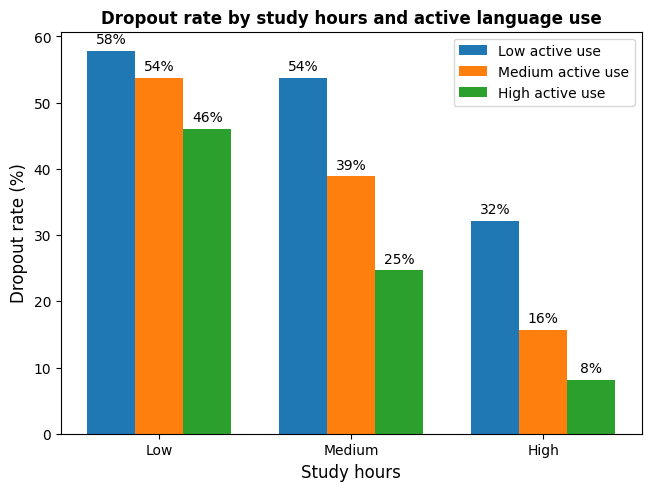

In [30]:
# Study-hour groups
study_groups = plot_data.index
x = np.arange(len(study_groups))

# Width of each bar
width = 0.25

fig, ax = plt.subplots(layout='constrained')

# Three active-use groups
ax.bar(x - width, plot_data['Low'], width,label='Low active use')

ax.bar(
    x,
    plot_data['Medium'],
    width,
    label='Medium active use'
)

ax.bar(
    x + width,
    plot_data['High'],
    width,
    label='High active use'
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3)

# Labels and title
ax.set_ylabel('Dropout rate (%)', size =12)
ax.set_xlabel('Study hours', size=12)
ax.set_title('Dropout rate by study hours and active language use', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(study_groups)

ax.legend()

plt.show()

<a id="sec-5-7"></a>

### 5.7 Knowledge of Prior and Related Languages

In [31]:
df['prior_languages'].value_counts().sort_index()

prior_languages
0    20224
1    16071
2     6560
3     1731
4      349
5       65
Name: count, dtype: int64

In [32]:
df.groupby('prior_languages')['dropped_out'].mean()*100

prior_languages
0    37.119264
1    37.191214
2    36.890244
3    35.875217
4    37.249284
5    38.461538
Name: dropped_out, dtype: float64

Prior language knowledge showed little difference in dropout rates, dropout remained around 36–38% across all groups. This suggests that the number of languages learners already knew was not strongly associated with dropout in this dataset.

In [33]:
df.groupby('related_language')['dropped_out'].mean().mul(100).round(2)

related_language
0    38.52
1    33.72
Name: dropped_out, dtype: float64

Learners who already knew a language related to their target language had a slightly lower dropout rate (33.7%) than those who did not (38.5%), a difference of 4.8 percentage points.

<a id="sec-5-8"></a>

### 5.8 Average Learning Behaviours by Dropout Status

In [34]:
quality_variables = [
    'active_use_share',
    'speaking_practice',
    'immersion_months',
    'feedback_quality',
    'comprehensible_input_hours'
]

df.groupby('dropped_out')[quality_variables].mean()

,active_use_share,speaking_practice,immersion_months,feedback_quality,comprehensible_input_hours
dropped_out,,,,,
0,0.429339,6.238069,1.722839,5.059978,370.203743
1,0.348913,5.935053,0.951763,4.893637,225.948441


Learners who did not drop out averaged higher values on every behaviour measured. The clearest differences were in comprehensible input (370 vs 226 hours) and active use (42.9% vs 34.9% of study time). Additionally, Immersion was higher among learners who did not drop out (1.7 vs 1.0 months), while speaking practice (6.2 vs 5.9 out of 10) and feedback quality (5.1 vs 4.9 out of 10) differed only slightly.

The correlation analysis below ranks all of these variables by the strength of their association with dropout.

<a id="sec-6"></a>

## 6. Ranking the Factors Using Pearson Correlation

In [35]:
# Select numerical columns and calculate Pearson correlations
pearson_corr = df.select_dtypes(include='number').corr(method='pearson')

# Print correlations with dropout, from lowest to highest
print(pearson_corr['dropped_out'].sort_values())


reached_fluency              -0.572622
total_study_hours            -0.292110
comprehensible_input_hours   -0.271179
active_use_share             -0.193911
motivation                   -0.146853
consistency                  -0.142852
immersion_months             -0.136168
speaking_practice            -0.064946
related_language             -0.045722
feedback_quality             -0.037201
uses_srs                     -0.011531
accent_nativelike            -0.007711
prior_languages              -0.002974
age_started                   0.001185
fsi_category                  0.271023
dropped_out                   1.000000
Name: dropped_out, dtype: float64


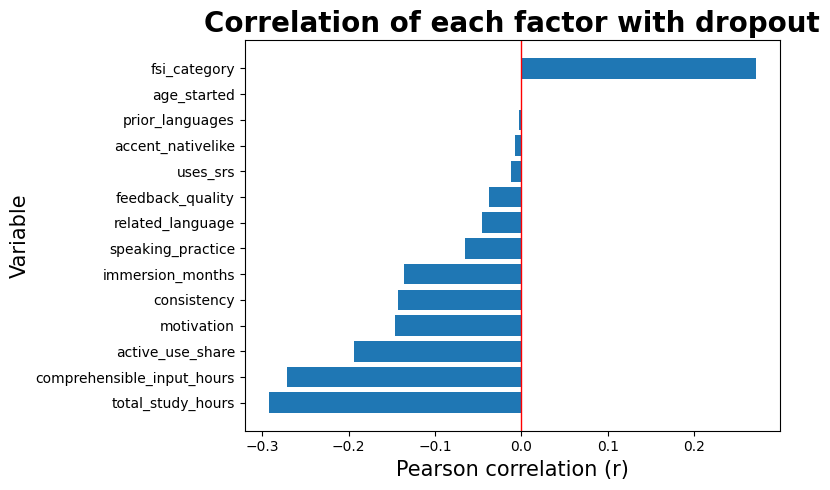

In [36]:
# Bar Chart of Pearson Correlation
dropout_corr = (pearson_corr['dropped_out'].drop(['dropped_out','reached_fluency']).sort_values())

plt.figure(figsize=(8, 5))

plt.barh(dropout_corr.index, dropout_corr.values)

plt.axvline(0, linewidth=1, color = 'red')

plt.xlabel("Pearson correlation (r)", fontsize=15)
plt.ylabel("Variable", fontsize=15)
plt.title("Correlation of each factor with dropout", fontsize=20,fontweight='bold')

plt.tight_layout()
plt.show()

<a id="sec-7"></a>

## 7. Loading the Data to PostgreSQL


In [37]:
import os
from sqlalchemy import create_engine

# Credentials are read from environment variables so no password is stored in the notebook
username = os.environ.get("PG_USER", "postgres")
password = os.environ["PG_PASSWORD"]
host = "localhost"
port = "5432"
database = "language_fluency"

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

table_name = "language_learners"
df.to_sql(table_name, engine, if_exists="replace", index=False)
print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")

KeyError: 'PG_PASSWORD'